<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%9613.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.datasets
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision.models import googlenet, GoogLeNet_Weights, resnet18

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed(0)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print("Пристрій:", device)

Пристрій: cpu


# Підготовка даних CIFAR10

In [ ]:
CIFAR_train = torchvision.datasets.CIFAR10('./', download=True, train=True)
CIFAR_test = torchvision.datasets.CIFAR10('./', download=True, train=False)

X_all = (torch.FloatTensor(CIFAR_train.data) / 255.).permute(0, 3, 1, 2)
y_all = torch.LongTensor(CIFAR_train.targets)
X_test_all = (torch.FloatTensor(CIFAR_test.data) / 255.).permute(0, 3, 1, 2)
y_test_all = torch.LongTensor(CIFAR_test.targets)

generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(X_all), generator=generator)
test_permutation = torch.randperm(len(X_test_all), generator=generator)

X_train, y_train = X_all[permutation[:10000]], y_all[permutation[:10000]]
X_val, y_val = X_all[permutation[10000:12000]], y_all[permutation[10000:12000]]
X_test, y_test = X_test_all[test_permutation[:2000]], y_test_all[test_permutation[:2000]]

print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([10000, 3, 32, 32]) torch.Size([2000, 3, 32, 32]) torch.Size([2000, 3, 32, 32])


Використовується той самий набір даних і те саме розбиття, що в практичній роботі №12: 10 000 зображень для навчання, 2000 для валідації та 2000 для фінальної перевірки. Значення пікселів ділиться на 255.

# Функції навчання та побудови графіків

In [ ]:
sns.set_style("darkgrid")
sns.set(rc={'figure.figsize': (15, 6)})

accuracies = {}
losses = {}
finals = {}

def augment_batch(x):
    flip = torch.rand(len(x), device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    padded = torch.nn.functional.pad(x, (4, 4, 4, 4), mode='reflect')
    dx, dy = np.random.randint(0, 9, size=2)
    return padded[:, :, dy:dy + 32, dx:dx + 32]

def train(net, X_train, y_train, X_val, y_val, batch_size=128, epoch_num=4, epoch_info_show=1,
          weight_decay=0, lr=1.0e-3, augment=False, verbose=True):
    net = net.to(device)
    loss = torch.nn.CrossEntropyLoss().to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)

    t = time.time()
    val_accuracy_history = []
    val_loss_history = []
    epoch_times = []
    X_val = X_val.to(device)
    y_val = y_val.to(device)

    for epoch in range(1, epoch_num + 1):
        epoch_start = time.time()
        order = np.random.permutation(len(X_train))
        for start_index in range(0, len(X_train), batch_size):
            optimizer.zero_grad()
            net.train()

            batch_indexes = order[start_index:start_index + batch_size]

            X_batch = X_train[batch_indexes].to(device)
            y_batch = y_train[batch_indexes].to(device)
            if augment:
                X_batch = augment_batch(X_batch)

            if net.__class__.__name__ == "GoogLeNet" and net.aux_logits:
                preds = net.forward(X_batch)
                loss_value1 = loss(preds[0], y_batch)
                loss_value2 = loss(preds[1], y_batch)
                loss_value3 = loss(preds[2], y_batch)
                loss_value = loss_value1 + 0.3 * loss_value2 + 0.3 * loss_value3
            else:
                preds = net.forward(X_batch)
                loss_value = loss(preds, y_batch)

            loss_value.backward()
            optimizer.step()

        net.eval()
        with torch.no_grad():
            val_preds = net.forward(X_val)
        val_loss_history.append(loss(val_preds, y_val).item())
        accuracy = (val_preds.argmax(dim=1) == y_val).float().mean().item()
        val_accuracy_history.append(accuracy)
        epoch_times.append(time.time() - epoch_start)

        if verbose and epoch % epoch_info_show == 0:
            print('Epoch: {} Time: {} Accuracy: {:.4f}'.format(
                epoch, time.strftime("%H:%M:%S", time.gmtime(time.time() - t)), accuracy))

    return net, val_accuracy_history, val_loss_history, float(np.mean(epoch_times))

def run(name, net, **kwargs):
    print('==', name)
    net, acc_history, loss_history, sec_per_epoch = train(net, X_train, y_train, X_val, y_val, **kwargs)
    net.eval()
    with torch.no_grad():
        test_logits = net.forward(X_test.to(device)).cpu()
    test_accuracy = (test_logits.argmax(dim=1) == y_test).float().mean().item()
    accuracies[name] = acc_history
    losses[name] = loss_history
    finals[name] = {
        'параметрів': sum(p.numel() for p in net.parameters()),
        'best val acc': max(acc_history),
        'val loss (мін)': min(loss_history),
        'test acc': test_accuracy,
        'хв / епоху': sec_per_epoch / 60,
        'logits': test_logits,
    }
    print('test accuracy: {:.4f}'.format(test_accuracy))
    del net

def acc_loss_graph(accuracies, losses, net_list):
    fig, (ax1, ax2) = plt.subplots(1, 2)

    for experiment_id in net_list:
        ax1.plot(range(1, len(accuracies[experiment_id]) + 1), accuracies[experiment_id], label=experiment_id)
    ax1.legend()
    ax1.set_title('Validation Accuracy')
    ax1.set_xlabel('epoch')
    fig.tight_layout()

    for experiment_id in net_list:
        ax2.plot(range(1, len(losses[experiment_id]) + 1), losses[experiment_id], label=experiment_id)
    ax2.legend()
    ax2.set_title('Validation Loss')
    ax2.set_xlabel('epoch')

    fig.tight_layout()
    plt.show()

def results_table(names):
    return pd.DataFrame({n: {k: v for k, v in finals[n].items() if k != 'logits'} for n in names}).T

Функція `train` така сама, як у попередніх роботах, з одним доповненням із теорії: якщо мережа є `GoogLeNet` з додатковими виходами, то втрата рахується як сума втрати основного виходу та втрат двох допоміжних, помножених на 0.3. Для перевірки на валідації використовується лише основний вихід.

# Реалізація GoogLeNet

In [ ]:
class Inception(nn.Module):
    def __init__(self, in_planes, n1x1, n3x3red, n3x3, n5x5red, n5x5, pool_planes):
        super(Inception, self).__init__()
        self.b1 = nn.Sequential(
            nn.Conv2d(in_planes, n1x1, kernel_size=1),
            nn.BatchNorm2d(n1x1),
            nn.ReLU(True),
        )

        self.b2 = nn.Sequential(
            nn.Conv2d(in_planes, n3x3red, kernel_size=1),
            nn.BatchNorm2d(n3x3red),
            nn.ReLU(True),
            nn.Conv2d(n3x3red, n3x3, kernel_size=3, padding=1),
            nn.BatchNorm2d(n3x3),
            nn.ReLU(True),
        )

        self.b3 = nn.Sequential(
            nn.Conv2d(in_planes, n5x5red, kernel_size=1),
            nn.BatchNorm2d(n5x5red),
            nn.ReLU(True),
            nn.Conv2d(n5x5red, n5x5, kernel_size=3, padding=1),
            nn.BatchNorm2d(n5x5),
            nn.ReLU(True),
            nn.Conv2d(n5x5, n5x5, kernel_size=3, padding=1),
            nn.BatchNorm2d(n5x5),
            nn.ReLU(True),
        )

        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_planes, pool_planes, kernel_size=1),
            nn.BatchNorm2d(pool_planes),
            nn.ReLU(True),
        )

    def forward(self, x):
        y1 = self.b1(x)
        y2 = self.b2(x)
        y3 = self.b3(x)
        y4 = self.b4(x)
        return torch.cat([y1, y2, y3, y4], 1)

class InceptionAux(nn.Module):
    def __init__(self, in_planes, num_classes):
        super(InceptionAux, self).__init__()

        self.conv = nn.Conv2d(in_planes, 128, kernel_size=1)
        self.fc1 = nn.Linear(2048, 1024)
        self.fc2 = nn.Linear(1024, num_classes)

    def forward(self, x):
        x = torch.nn.functional.adaptive_avg_pool2d(x, (4, 4))
        x = self.conv(x)
        x = torch.flatten(x, 1)
        x = torch.nn.functional.relu(self.fc1(x), inplace=True)
        x = torch.nn.functional.dropout(x, 0.7, training=self.training)
        x = self.fc2(x)
        return x

class GoogLeNet(nn.Module):
    def __init__(self, num_classes=10, aux_logits=True):
        super(GoogLeNet, self).__init__()
        self.pre_layers = nn.Sequential(
            nn.Conv2d(3, 192, kernel_size=3, padding=1),
            nn.BatchNorm2d(192),
            nn.ReLU(True),
        )
        self.aux_logits = aux_logits

        self.a3 = Inception(192, 64, 96, 128, 16, 32, 32)
        self.b3 = Inception(256, 128, 128, 192, 32, 96, 64)

        self.maxpool = nn.MaxPool2d(3, stride=2, padding=1)

        self.a4 = Inception(480, 192, 96, 208, 16, 48, 64)
        self.b4 = Inception(512, 160, 112, 224, 24, 64, 64)
        self.c4 = Inception(512, 128, 128, 256, 24, 64, 64)
        self.d4 = Inception(512, 112, 144, 288, 32, 64, 64)
        self.e4 = Inception(528, 256, 160, 320, 32, 128, 128)
        self.a5 = Inception(832, 256, 160, 320, 32, 128, 128)
        self.b5 = Inception(832, 384, 192, 384, 48, 128, 128)

        if aux_logits:
            self.aux1 = InceptionAux(512, num_classes)
            self.aux2 = InceptionAux(528, num_classes)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.2)
        self.linear = nn.Linear(1024, num_classes)

    def forward(self, x):
        out = self.pre_layers(x)
        out = self.a3(out)
        out = self.b3(out)
        out = self.maxpool(out)
        out = self.a4(out)
        aux_defined = self.training and self.aux_logits
        if aux_defined:
            aux1 = self.aux1(out)
        else:
            aux1 = None
        out = self.b4(out)
        out = self.c4(out)
        out = self.d4(out)
        if aux_defined:
            aux2 = self.aux2(out)
        else:
            aux2 = None
        out = self.e4(out)
        out = self.maxpool(out)
        out = self.a5(out)
        out = self.b5(out)
        out = self.avgpool(out)
        out = out.view(out.size(0), -1)
        out = self.dropout(out)
        out = self.linear(out)
        if aux_defined:
            return out, aux2, aux1
        else:
            return out

model = GoogLeNet()
print("Параметрів:", sum(p.numel() for p in model.parameters()))
model.eval()
with torch.no_grad():
    print("Вихід (eval):", tuple(model(torch.randn(2, 3, 32, 32)).shape))
model.train()
outputs = model(torch.randn(2, 3, 32, 32))
print("Виходи (train):", [tuple(o.shape) for o in outputs])

Параметрів: 10516478
Вихід (eval): (2, 10)
Виходи (train): [(2, 10), (2, 10), (2, 10)]


Реалізація повторює теорію. Блок Inception складається з чотирьох паралельних гілок, результати яких з'єднуються за каналами: згортка 1 на 1, згортка 1 на 1 і 3 на 3, згортка 1 на 1 і дві згортки 3 на 3 (замість однієї 5 на 5) та max pooling 3 на 3 із згорткою 1 на 1. Допоміжні виходи `InceptionAux` підключаються після блоків `a4` і `d4` та лише під час навчання додають градієнт до початкових шарів. Для зображень 32 на 32 використовується варіант початкової частини з однією згорткою 3 на 3 (192 канали), який наведено в теорії у коментарі, а не стандартна початкова частина для зображень 224 на 224. У коді також виправлено дві дрібниці: допоміжні виходи повертаються лише під час навчання, а в кінці перед повнозв'язним шаром застосовується Dropout.

# Допоміжні мережі для порівняння

In [ ]:
class Normalized(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        return self.net((x - self.mean) / self.std)

def pretrained_googlenet():
    net = googlenet(weights=GoogLeNet_Weights.IMAGENET1K_V1)
    net.aux_logits = False
    net.aux1 = None
    net.aux2 = None
    net.fc = nn.Linear(1024, 10)
    return Normalized(net)

def scratch_googlenet():
    net = googlenet(weights=None, aux_logits=False, init_weights=True)
    net.fc = nn.Linear(1024, 10)
    return Normalized(net)

class BasicBlock(nn.Module):
    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(nn.Conv2d(in_planes, planes, 1, stride, bias=False), nn.BatchNorm2d(planes))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.shortcut(x))

class ResNet20(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, 1, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        layers, in_planes = [], 16
        for planes, stride in ((16, 1), (32, 2), (64, 2)):
            for i in range(3):
                layers.append(BasicBlock(in_planes, planes, stride if i == 0 else 1))
                in_planes = planes
        self.layers = nn.Sequential(*layers)
        self.linear = nn.Linear(64, num_classes)

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.layers(out)
        return self.linear(torch.nn.functional.adaptive_avg_pool2d(out, 1).flatten(1))

for name, factory in (('GoogLeNet (власна)', GoogLeNet), ('GoogLeNet (torchvision, навчена)', pretrained_googlenet),
                      ('ResNet20', ResNet20)):
    print(name, 'параметрів:', sum(p.numel() for p in factory().parameters()))

GoogLeNet (власна) параметрів: 10516478
GoogLeNet (torchvision, навчена) параметрів: 5610154
ResNet20 параметрів: 272474


Для порівняння використовуються вбудована в torchvision архітектура GoogLeNet із заздалегідь навченими на ImageNet вагами (її останній шар замінено на шар із 10 виходами, а допоміжні виходи вимкнено, як описано в теорії про transfer learning), вона ж з випадковою ініціалізацією, ResNet20 і ResNet18 із практичної роботи №12. Для мереж із ImageNet вхідні зображення додатково нормуються за середнім і стандартним відхиленням ImageNet.

# Завдання 1. Порівняння GoogLeNet з вбудованою та ResNet

> 1. Реалізуйте архітектуру GoogLeNet та порівняйте з вбудованою заздалегідь навченою архітектурою, та архітекторами ResNet. Яка архітектура дає кращий результат?

== GoogLeNet (власна)


Epoch: 1 Time: 00:27:30 Accuracy: 0.4245


Epoch: 2 Time: 00:34:17 Accuracy: 0.5205


Epoch: 3 Time: 00:41:00 Accuracy: 0.5305


Epoch: 4 Time: 00:47:44 Accuracy: 0.6195


test accuracy: 0.6445


... (17 outputs left out)

Epoch: 2 Time: 00:01:21 Accuracy: 0.4195


Epoch: 3 Time: 00:02:07 Accuracy: 0.4355


Epoch: 4 Time: 00:02:47 Accuracy: 0.4985


test accuracy: 0.5180


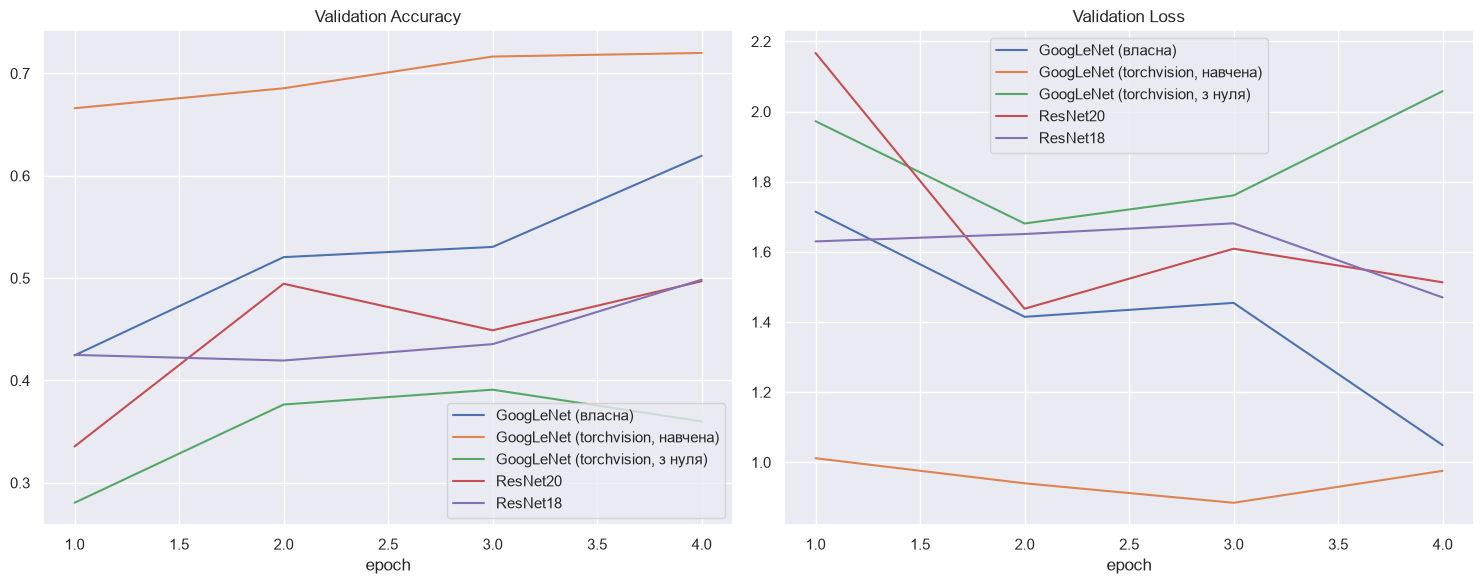

                                  параметрів  best val acc  val loss (мін)  test acc  хв / епоху
GoogLeNet (власна)                10516478.0        0.6195          1.0489    0.6445     11.9353
GoogLeNet (torchvision, навчена)   5610154.0        0.7200          0.8845    0.7130      0.9130
GoogLeNet (torchvision, з нуля)    5610154.0        0.3910          1.6809    0.3710      0.9087
ResNet20                            272474.0        0.4970          1.4378    0.5150      0.4535
ResNet18                          11181642.0        0.4985          1.4700    0.5180      0.6991


In [ ]:
run('GoogLeNet (власна)', GoogLeNet(), epoch_num=4)
run('GoogLeNet (torchvision, навчена)', pretrained_googlenet(), epoch_num=4)
run('GoogLeNet (torchvision, з нуля)', scratch_googlenet(), epoch_num=4)
run('ResNet20', ResNet20(), epoch_num=4)
run('ResNet18', resnet18(num_classes=10), epoch_num=4)

names = ['GoogLeNet (власна)', 'GoogLeNet (torchvision, навчена)', 'GoogLeNet (torchvision, з нуля)', 'ResNet20', 'ResNet18']
acc_loss_graph(accuracies, losses, names)
print(results_table(names).round(4).to_string())

**Відповідь.** Найкращий результат дає вбудована в torchvision GoogLeNet із заздалегідь навченими вагами: test accuracy 0.713 (validation 0.720) за 4 епохи. Власна реалізація GoogLeNet, навчена з нуля, дає 0.645 (validation 0.620), ResNet18 і ResNet20 дають 0.518 і 0.515. Та сама вбудована архітектура GoogLeNet без попередніх ваг, навчена з нуля, дає лише 0.371. Різниця між навченою й ненавченою версією (+34 п.п.) показує користь transfer learning: ваги, отримані на ImageNet, дають корисні фільтри навіть для зображень 32 на 32, і за 4 епохи на 10 000 зображень їх достатньо лише донавчити (з останнім шаром на 10 виходів).

Власна GoogLeNet точніша за обидві ResNet (0.645 проти 0.52), бо має більше ємності (10.5 млн параметрів) і працює на повній роздільній здатності: початкова частина однією згорткою не зменшує зображення 32 на 32 до блоків Inception. Ціна цього велика: близько 12 хвилин на епоху на CPU проти 0.45 хвилини у ResNet20 і 0.9 хвилини у вбудованої GoogLeNet, яка стискає зображення вже на початку. Тобто власна GoogLeNet у 26 разів повільніша за ResNet20. ResNet20 має лише 0.27 млн параметрів, тож за співвідношенням якості й вартості вона ефективніша, а за найвищою точністю при обмеженому часі навчання виграє заздалегідь навчена GoogLeNet. Усі значення отримано одним запуском, тому малі різниці (наприклад, між ResNet18 і ResNet20) не значущі.

# Завдання 2. Власні оптимізації

> 2. Спробуйте власні оптимізації, щоб покращити результат: модифікуйте архітектуру, додайте аугментацію, можете створити ансамбль із декількох мереж, тощо.

== GoogLeNet (навчена) + аугментація


Epoch: 1 Time: 00:00:56 Accuracy: 0.6415


Epoch: 2 Time: 00:01:50 Accuracy: 0.7130


Epoch: 3 Time: 00:02:45 Accuracy: 0.6715


Epoch: 4 Time: 00:03:40 Accuracy: 0.7350


test accuracy: 0.7375
== ResNet20 + аугментація


Epoch: 1 Time: 00:00:27 Accuracy: 0.3550


Epoch: 2 Time: 00:00:54 Accuracy: 0.4370


Epoch: 3 Time: 00:01:21 Accuracy: 0.5080


Epoch: 4 Time: 00:01:49 Accuracy: 0.3835


test accuracy: 0.3910


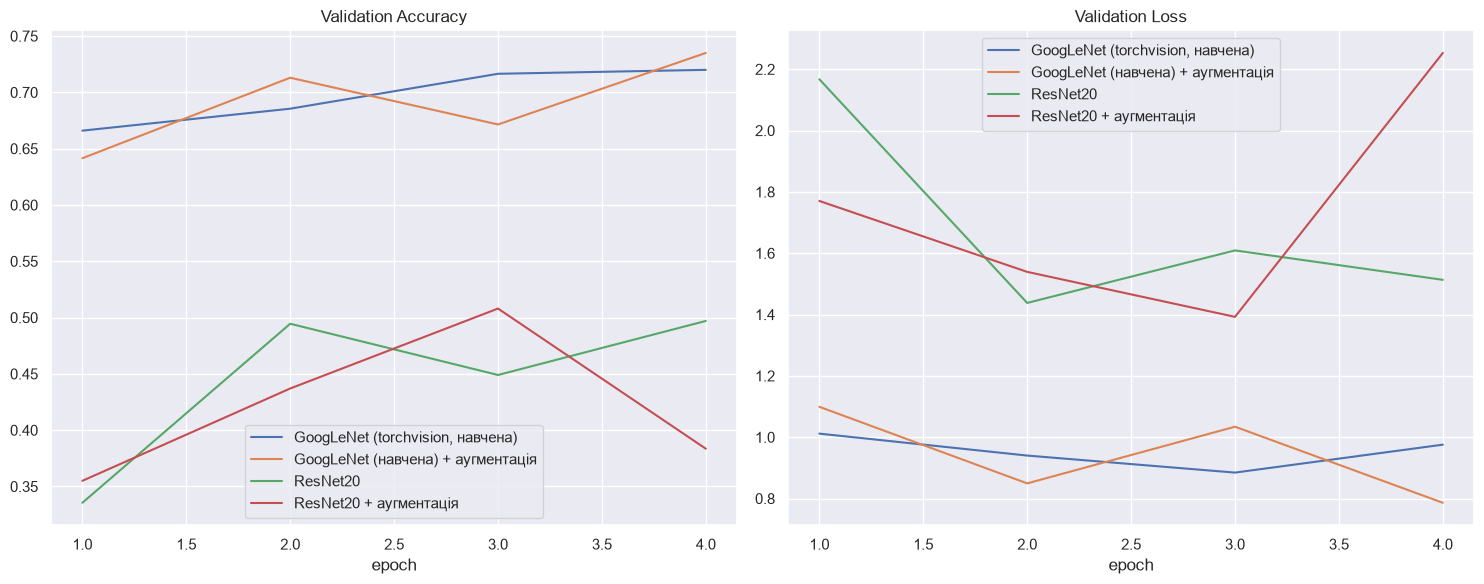

                                   параметрів  best val acc  val loss (мін)  test acc  хв / епоху
GoogLeNet (torchvision, навчена)    5610154.0         0.720          0.8845    0.7130      0.9130
GoogLeNet (навчена) + аугментація   5610154.0         0.735          0.7861    0.7375      0.9168
ResNet20                             272474.0         0.497          1.4378    0.5150      0.4535
ResNet20 + аугментація               272474.0         0.508          1.3924    0.3910      0.4547


In [ ]:
run('GoogLeNet (навчена) + аугментація', pretrained_googlenet(), epoch_num=4, augment=True)
run('ResNet20 + аугментація', ResNet20(), epoch_num=4, augment=True)

names = ['GoogLeNet (torchvision, навчена)', 'GoogLeNet (навчена) + аугментація', 'ResNet20', 'ResNet20 + аугментація']
acc_loss_graph(accuracies, losses, names)
print(results_table(names).round(4).to_string())

Аугментація складається з випадкового відображення кожного зображення по горизонталі та випадкового зсуву (кадрування з відступом 4 пікселі) для кожного батча.

In [ ]:
def ensemble_accuracy(names):
    probs = torch.stack([torch.softmax(finals[n]['logits'], dim=1) for n in names]).mean(dim=0)
    return (probs.argmax(dim=1) == y_test).float().mean().item()

ensembles = {
    'навчена GoogLeNet + аугментація, ResNet20 + аугментація': ['GoogLeNet (навчена) + аугментація', 'ResNet20 + аугментація'],
    'власна GoogLeNet + навчена GoogLeNet': ['GoogLeNet (власна)', 'GoogLeNet (torchvision, навчена)'],
    'усі п\'ять мереж із завдання 1': ['GoogLeNet (власна)', 'GoogLeNet (torchvision, навчена)',
                                     'GoogLeNet (torchvision, з нуля)', 'ResNet20', 'ResNet18'],
    'усі сім мереж': [n for n in finals],
}

rows = {n: finals[n]['test acc'] for n in finals}
for title, members in ensembles.items():
    rows[title] = ensemble_accuracy(members)

summary = pd.Series(rows, name='test acc').sort_values(ascending=False)
print(summary.round(4).to_string())

усі сім мереж                                              0.7690
власна GoogLeNet + навчена GoogLeNet                       0.7460
усі п'ять мереж із завдання 1                              0.7460
GoogLeNet (навчена) + аугментація                          0.7375
GoogLeNet (torchvision, навчена)                           0.7130
навчена GoogLeNet + аугментація, ResNet20 + аугментація    0.6690
GoogLeNet (власна)                                         0.6445
ResNet18                                                   0.5180
ResNet20                                                   0.5150
ResNet20 + аугментація                                     0.3910
GoogLeNet (torchvision, з нуля)                            0.3710


**Результат.** Аугментація (випадкове відображення та зсув) покращила заздалегідь навчену GoogLeNet: test accuracy 0.738 проти 0.713, validation 0.735 проти 0.720, validation loss 0.786 проти 0.885. Для ResNet20 аугментація дала нестабільний результат: найкраща validation accuracy вища (0.508 проти 0.497), але на тесті після останньої епохи 0.391 проти 0.515. Імовірно, за 4 епохи статистики пакетної нормалізації в ResNet20 не встигли стабілізуватись на аугментованих зображеннях і результат на останній епосі нестійкий, тому цей результат не слід вважати доказом шкоди аугментації.

Ансамбль усереднює ймовірності класів кількох мереж. Найкращий результат у цій роботі дає ансамбль з усіх семи мереж: 0.769, що краще за найкращу окрему мережу (0.738). Ансамбль із власної та навченої GoogLeNet дає 0.746, ансамбль із п'яти мереж із завдання 1 також 0.746, тобто приріст відносно найкращої навченої GoogLeNet (0.713) становить близько 3 п.п. Ансамбль із двох мереж з аугментацією, один з яких слабкий ResNet20 (0.391), дає лише 0.669: слабкий учасник знижує результат. Отже, найкраща окрема модель це навчена GoogLeNet з аугментацією (0.738), а найкращий загальний результат дає ансамбль (0.769).

# Висновки

У цьому практикумі ми навчились будувати архітектуру GoogLeNet з блоків Inception (чотири паралельні гілки з згортками 1 на 1, 3 на 3 і пулінгом, результати яких з'єднуються за каналами), використовувати допоміжні виходи, які додають градієнт до початкових шарів, і порівнювати її з вбудованою навченою моделлю та з ResNet. Метою завдання було засвоїти принцип роботи та побудови архітектури GoogLeNet, і її досягнуто. Усі порівняння виконано на підвибірці CIFAR10 (10 000 зображень для навчання) по 4 епохи одним запуском.

**Вибір оптимальної мережі.** Найкраща окрема мережа це вбудована GoogLeNet із заздалегідь навченими на ImageNet вагами та аугментацією: test accuracy 0.738. Вона має 5.6 млн параметрів і навчається близько 0.9 хвилини на епоху. Без аугментації вона дає 0.713, а та сама архітектура, навчена з нуля, лише 0.371, тобто попереднє навчання дає найбільший виграш. Власна реалізація GoogLeNet з нуля дає 0.645, але потребує приблизно 12 хвилин на епоху. Найвищий результат дає ансамбль із семи мереж: 0.769.

**Порівняння GoogLeNet і ResNet з минулої роботи.** У цій роботі ResNet18 та ResNet20 дали по 0.52 (з батчем 128 і 4 епохами), а власна GoogLeNet 0.645, тобто GoogLeNet точніша, але в 26 разів повільніша за ResNet20 і має в 39 разів більше параметрів (10.5 проти 0.27 млн). У роботі №12 найкраща ResNet20 дала 0.62 (з батчем 16 і 5 епохами), тож результат ResNet значно залежить від гіперпараметрів навчання, і прямо порівнювати числа з різних робіт не можна. Також в обох випадках використовувались різні кількості епох. Загалом при обмеженому часі навчання і малому наборі даних практично найвигідніше використовувати попередньо навчену мережу та донавчати її, а при навчанні з нуля GoogLeNet точніша за ResNet, але значно дорожча.

# Контрольні питання

**1. Які особливості архітектури Google Net?**

GoogLeNet, також відома як Inception Module, є переможцем конкурсу ILSVRC 2014 (6,67% помилок у змаганні). Вона складається з 22 шарів у глибину, що зменшує кількість параметрів із 60 мільйонів (AlexNet) до 4 мільйонів. У ній немає повнозв'язних шарів на виході моделі: замість них після усереднювального пулінгу стоїть один лінійний шар. На початку розташована невелика підмережа Stem Network (prenet) із трьох згорткових шарів і двох шарів пулінгу. На схемі мережі видно невеликі проміжні «відростки», це допоміжні класифікаційні виходи, які вводять додатковий градієнт на початкових шарах (їх підключають після 4-го та 7-го блоків Inception: AvgPool, згортка 1 на 1, два повнозв'язні шари, softmax). Основою мережі є модуль Inception.

**2. Що являє собою Inception block?**

Inception block сам по собі є невеликою локальною мережею. Вся його робота полягає в паралельному застосуванні кількох фільтрів до вхідного зображення, після чого результати об'єднуються і створюється вихідний сигнал, який переходить на наступний шар. У нашій реалізації блок має чотири гілки: згортка 1 на 1, згортка 1 на 1 і потім 3 на 3, згортка 1 на 1 і потім згортки (замість 5 на 5 дві по 3 на 3), та max pooling 3 на 3 із наступною згорткою 1 на 1. Згортки 1 на 1 перед великими фільтрами зменшують кількість каналів, а виходи гілок з'єднуються за каналами через `torch.cat`.